# Geographically weighted PCA

Principal component analysis (PCA) summarises a set of correlated variables with
a few components. Ordinary PCA fits **one** set of components for the whole study
area, which assumes the relationships among the variables are the same
everywhere. Geographically weighted PCA (GWPCA) {cite:p}`harris2011,harris2015`
drops that assumption: it runs a separate, kernel-weighted PCA at every
location, so the loadings, and how much variance the leading components capture,
can vary across space.

Unlike the regression models in `spml`, GWPCA is unsupervised. It takes a
feature matrix `X` and no target `y`.

This notebook follows the structure of Chris Brunsdon's
[GWPCA tutorial](https://rpubs.com/chrisbrunsdon/99675) for the R package
`GWmodel`, using the Guerry data instead of the Baltic soils data.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from geodatasets import get_path
from sklearn.decomposition import PCA

from spml.decomposition import GWPCA

## Data

The example uses the [Guerry](https://geodacenter.github.io/data-and-lab//Guerry/)
dataset of 85 French departments in the 1830s, with six of its "moral
statistics": crimes against persons and property, literacy, donations to the
poor, illegitimate births and suicides.

In [2]:
gdf = gpd.read_file(get_path("geoda.guerry"))
points = gdf.representative_point()

variables = ["Crm_prs", "Crm_prp", "Litercy", "Donatns", "Infants", "Suicids"]
X = gdf[variables]
X.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
Crm_prs,19960.941176,7299.241801,5883.0,37014.0
Crm_prp,7881.341176,3048.615285,1368.0,20235.0
Litercy,39.141176,17.434335,12.0,74.0
Donatns,6723.317647,4863.244310,1246.0,27830.0
Infants,18982.929412,8850.552556,2660.0,62486.0
Suicids,36516.800000,31498.318790,3460.0,163241.0


## Global PCA as a baseline

Start with ordinary PCA on the globally standardized variables (z-scores). This
is the "one structure everywhere" answer that GWPCA is compared against.

In [3]:
X_std = (X - X.mean()) / X.std(ddof=0)
global_pca = PCA().fit(X_std)

pd.Series(
    global_pca.explained_variance_ratio_,
    index=[f"PC{i + 1}" for i in range(len(variables))],
    name="explained variance ratio",
).round(3)

PC1    0.357
PC2    0.200
PC3    0.184
PC4    0.111
PC5    0.091
PC6    0.057
Name: explained variance ratio, dtype: float64

The first two global components capture a little over half of the variance.
Their loadings show which variables drive each component:

In [4]:
global_loadings = pd.DataFrame(
    global_pca.components_[:2], index=["PC1", "PC2"], columns=variables
)
global_loadings.round(2)

,Crm_prs,Crm_prp,Litercy,Donatns,Infants,Suicids
PC1,0.07,0.51,-0.51,0.11,0.45,0.51
PC2,0.59,-0.09,-0.13,0.70,0.10,-0.36


PC1 contrasts literacy with property crime, illegitimate births and suicides.
PC2 is mostly crime against persons and donations to the poor, set against
suicides.

The loadings say *what* the components are, but not *where* they matter.
Mapping the global component scores shows that even the global components have
a clear geography:

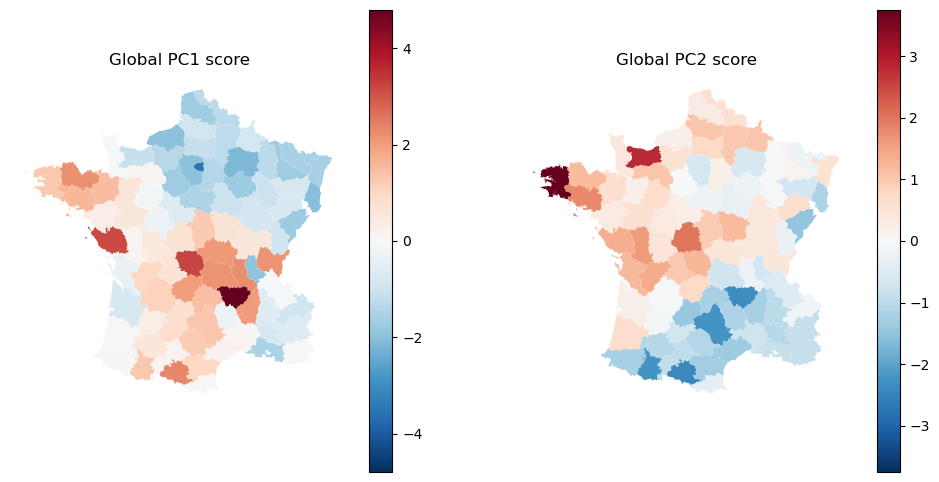

In [5]:
global_scores = pd.DataFrame(
    global_pca.transform(X_std)[:, :2], columns=["PC1", "PC2"], index=gdf.index
)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, pc in zip(axes, ["PC1", "PC2"], strict=True):
    vmax = np.abs(global_scores[pc]).max()
    gdf.assign(score=global_scores[pc]).plot(
        "score", ax=ax, cmap="RdBu_r", vmin=-vmax, vmax=vmax, legend=True
    )
    ax.set_title(f"Global {pc} score")
    ax.set_axis_off()

### Global outliers

Departments with extreme global scores are unusual compared with France as a
whole. A box plot of the PC1 scores flags one, Haute-Loire:

Dprtmnt
Haute-Loire    4.8
Name: PC1, dtype: float64

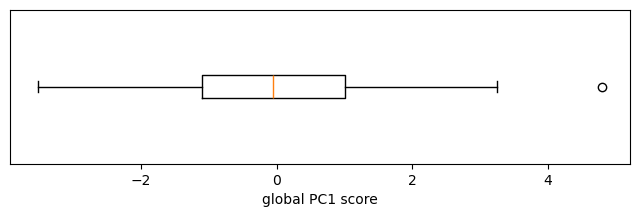

In [6]:
def boxplot_outliers(values):
    """Labels of values beyond the box-plot whiskers (1.5 x IQR)."""
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return values[(values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)].index


pc1_scores = global_scores["PC1"].set_axis(gdf["Dprtmnt"])
fig, ax = plt.subplots(figsize=(8, 2))
ax.boxplot(pc1_scores, vert=False)
ax.set_yticks([])
ax.set_xlabel("global PC1 score")

global_outliers = boxplot_outliers(pc1_scores)
pc1_scores[global_outliers].round(2)

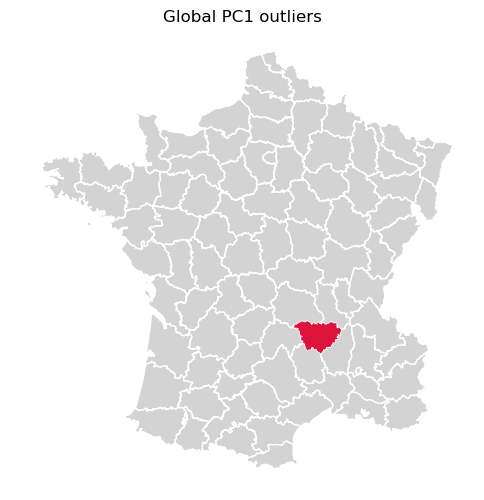

In [7]:
ax = gdf.plot(color="lightgrey", edgecolor="white", figsize=(6, 6))
gdf[gdf["Dprtmnt"].isin(global_outliers)].plot(ax=ax, color="crimson")
ax.set_title("Global PC1 outliers")
ax.set_axis_off()

## Fitting GWPCA

`GWPCA` takes the same neighbourhood settings as the other geographically
weighted models. Here each local PCA uses the 30 nearest departments (an
adaptive bandwidth, `fixed=False`), weighted with a bisquare kernel, and keeps
two components. `standardize=True` (the default) z-scores the variables once,
globally, before the local fits.

```{note}
`spml` has no built-in bandwidth selection for GWPCA yet. The bandwidth of 30
is a first guess; later in this notebook the bandwidth is chosen by
cross-validation, computed by hand.
```

In [8]:
gwpca = GWPCA(n_components=2, bandwidth=30, fixed=False, kernel="bisquare")
gwpca.fit(X, geometry=points)

,n_components,2
,bandwidth,30
,fixed,False
,kernel,'bisquare'
,include_focal,True
,standardize,True
,graph,None
,n_jobs,-1
,fit_global_model,True
,keep_models,False
,temp_folder,None


The fitted model holds one PCA per department. Local loadings are available as
an array shaped `(n_locations, n_components, n_features)`, like the
`components_` attribute of scikit-learn's PCA, but with one set per location:

In [9]:
gwpca.components_.shape

(85, 2, 6)

and as a tidy table indexed by location and component:

In [10]:
gwpca.local_loadings_.head(6).round(2)

Crm_prs  Crm_prp  Litercy  Donatns  Infants  Suicids
location component                                                      
0        PC1           0.13     0.62    -0.40     0.05     0.47     0.47
         PC2           0.66     0.33     0.42    -0.02     0.23    -0.48
1        PC1           0.80     0.56    -0.01     0.03     0.21     0.11
         PC2          -0.17     0.24     0.86    -0.40     0.09    -0.01
2        PC1           0.17     0.74    -0.17     0.07     0.20     0.59
         PC2           0.66     0.40     0.24     0.02    -0.15    -0.57

The global PCA fitted on the same data is kept as a baseline in
`global_model_`.

In [11]:
gwpca.global_model_.explained_variance_ratio_.round(3)

array([0.357, 0.2  ])

## How much variance do two components capture locally?

`proportion_total_var_` (PTV) is the share of local variance captured by the
retained components. Mapping it shows where the six variables can be summarised
well by two components and where the local structure is more complex.

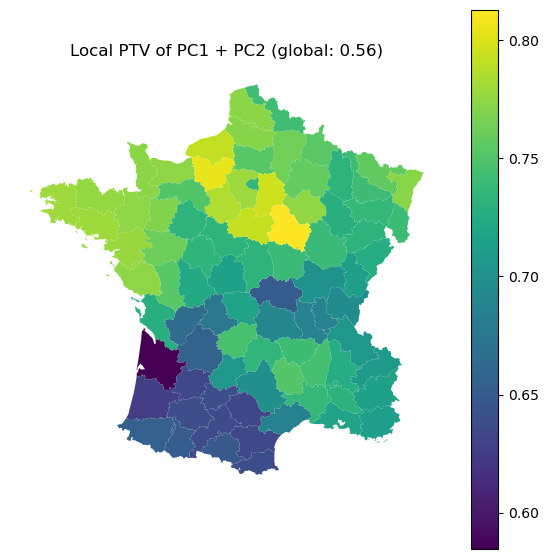

In [12]:
global_ptv = gwpca.global_model_.explained_variance_ratio_.sum()

ax = gdf.assign(ptv=gwpca.proportion_total_var_).plot(
    "ptv", legend=True, cmap="viridis", figsize=(7, 7)
)
ax.set_title(f"Local PTV of PC1 + PC2 (global: {global_ptv:.2f})")
ax.set_axis_off()

Every department's local PTV is higher than the global value. Within a
neighbourhood the variables are more strongly related than they are across
France as a whole, so a global PCA understates how well a few components
describe the data locally.

The share captured by the first component alone is in
`explained_variance_ratio_`:

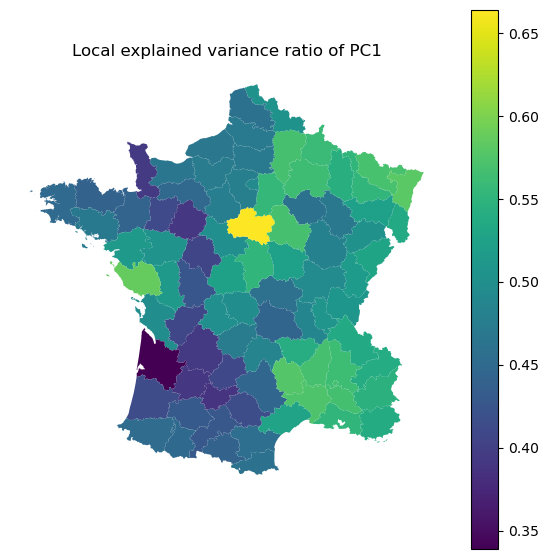

In [13]:
ax = gdf.assign(pc1=gwpca.explained_variance_ratio_["PC1"]).plot(
    "pc1", legend=True, cmap="viridis", figsize=(7, 7)
)
ax.set_title("Local explained variance ratio of PC1")
ax.set_axis_off()

## Which variable dominates locally?

The classic GWPCA map is the *winning variable*: at each location, the variable
with the largest absolute loading on a local component. `winning_variable_`
gives it for PC1:

In [14]:
gwpca.winning_variable_.value_counts()

winning_variable
Suicids    22
Crm_prp    21
Crm_prs    20
Infants    14
Donatns     5
Litercy     3
Name: count, dtype: int64

The same idea works for any component. Here is the winning variable on PC1
and on PC2, side by side:

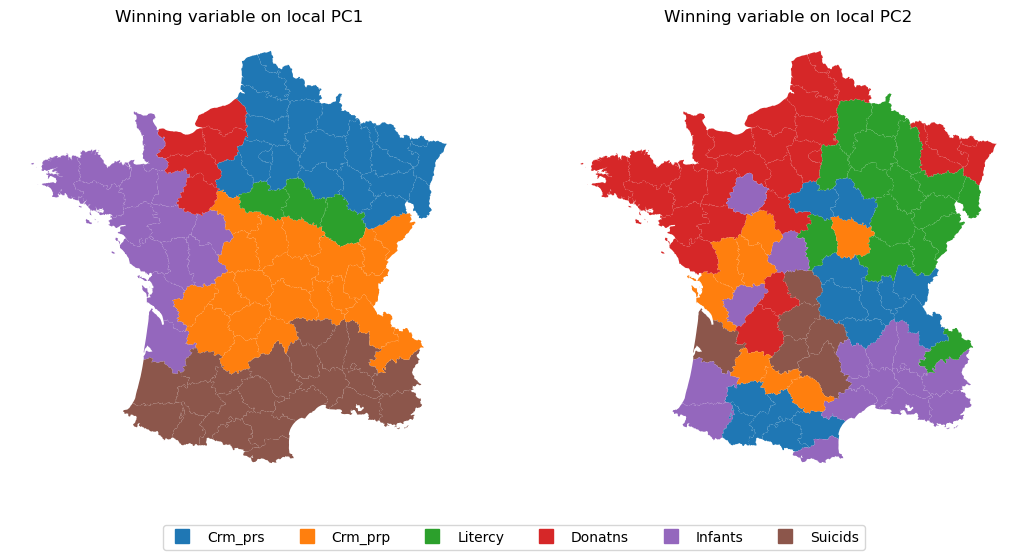

In [15]:
def winning_variable(model, component):
    loadings = model.local_loadings_.xs(component, level="component")
    return loadings.abs().idxmax(axis=1)


colors = dict(zip(variables, plt.cm.tab10.colors, strict=False))
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, pc in zip(axes, ["PC1", "PC2"], strict=True):
    winner = winning_variable(gwpca, pc)
    gdf.plot(color=winner.map(colors), ax=ax)
    ax.set_title(f"Winning variable on local {pc}")
    ax.set_axis_off()
handles = [
    plt.Line2D([], [], marker="s", ls="", color=c, ms=10) for c in colors.values()
]
fig.legend(handles, colors.keys(), loc="lower center", ncol=len(variables));

Globally, PC1 is a mix of property crime, literacy, illegitimate births and
suicides. Locally, different variables lead in different regions, which is the
kind of spatial heterogeneity a single global PCA hides.

## Local loadings

The winning variable shows only the largest loading. To see the whole first
component, map the loading of every variable on local PC1:

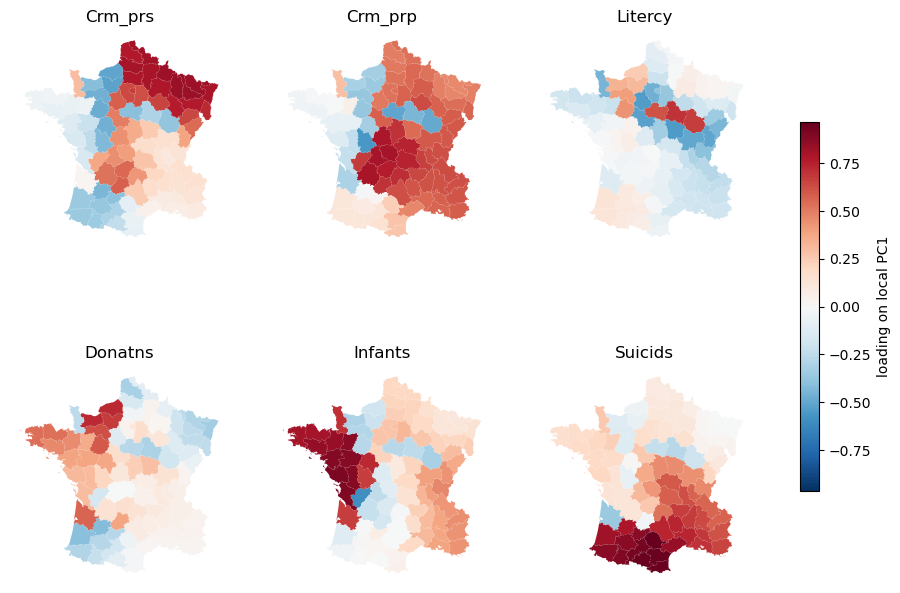

In [16]:
pc1 = gwpca.local_loadings_.xs("PC1", level="component")
vmax = np.abs(pc1.to_numpy()).max()

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, var in zip(axes.flat, variables, strict=True):
    gdf.assign(loading=pc1[var]).plot(
        "loading", ax=ax, cmap="RdBu_r", vmin=-vmax, vmax=vmax
    )
    ax.set_title(var)
    ax.set_axis_off()
fig.colorbar(
    plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(-vmax, vmax)),
    ax=axes,
    shrink=0.6,
    label="loading on local PC1",
);

### Glyph plot

A glyph plot puts all of a location's loadings into a single symbol. Each
department gets a star with one spoke per variable; the spoke's length is the
size of the loading and its colour is the sign (red for negative). Changes in
the shape of the stars across the map show where the local component changes.

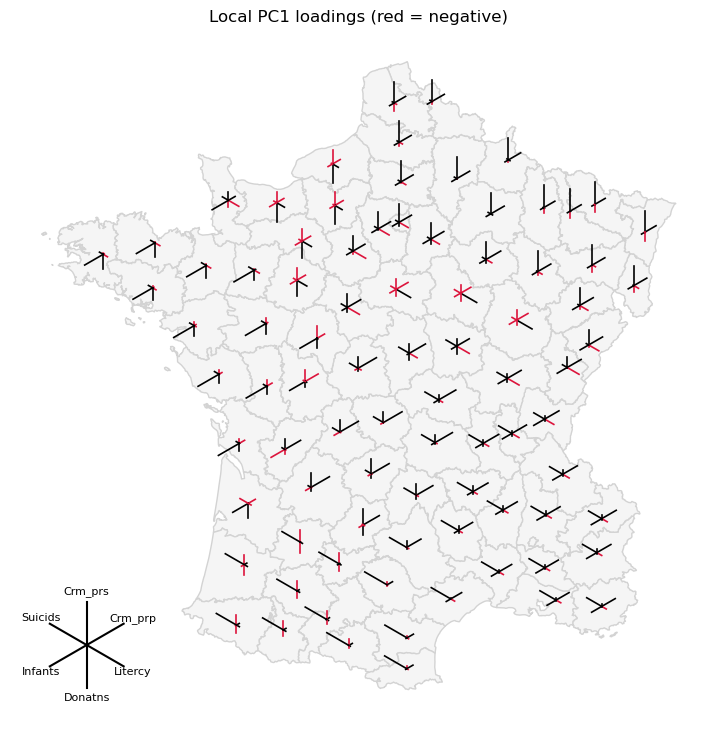

In [17]:
def glyph_plot(loadings, points, ax, radius=40_000):
    """Star glyphs of local loadings: one spoke per variable, red if negative."""
    n_vars = loadings.shape[1]
    angles = np.pi / 2 - 2 * np.pi * np.arange(n_vars) / n_vars
    scale = radius / np.abs(loadings.to_numpy()).max()
    for (x, y), row in zip(
        zip(points.x, points.y, strict=True), loadings.to_numpy(), strict=True
    ):
        for angle, value in zip(angles, row, strict=True):
            length = abs(value) * scale
            ax.plot(
                [x, x + length * np.cos(angle)],
                [y, y + length * np.sin(angle)],
                color="crimson" if value < 0 else "black",
                lw=1.2,
            )
    return angles


ax = gdf.plot(color="whitesmoke", edgecolor="lightgrey", figsize=(9, 9))
angles = glyph_plot(pc1, points, ax)
ax.set_title("Local PC1 loadings (red = negative)")
ax.set_axis_off()

# key: which spoke is which variable
key = ax.inset_axes([0.0, 0.0, 0.22, 0.22])
for angle, var in zip(angles, variables, strict=True):
    key.plot([0, np.cos(angle)], [0, np.sin(angle)], color="black")
    key.text(
        1.25 * np.cos(angle),
        1.25 * np.sin(angle),
        var,
        ha="center",
        va="center",
        fontsize=8,
    )
key.set_xlim(-1.8, 1.8)
key.set_ylim(-1.6, 1.6)
key.set_aspect("equal")
key.set_axis_off()

```{warning}
An eigenvector is only defined up to its sign, and neighbouring locations can
also swap the order of components whose eigenvalues are close. `GWPCA` makes
the largest loading of each component positive at every location, but it does
not yet align components *across* locations. An abrupt change of colour
between neighbours, in the loading maps or the glyphs, can therefore be a sign
flip or a component swap rather than a real change in structure. Maps of
absolute loadings, PTV and the winning variable are not affected.
```

## Local scores

`local_scores_` follows the convention of the R package `GWmodel`: every local
PCA scores **all of the observations in its neighbourhood**, not just the
location it was fitted for. The table is indexed by `(location, neighbor)`:

In [18]:
gwpca.local_scores_.head().round(2)

PC1   PC2
location neighbor            
0        0         2.56  2.01
         2         1.83 -1.28
         3        -0.57 -0.07
         4        -0.75  0.95
         5         2.01 -0.63

The scores are the globally standardized values multiplied by the local
loadings, without subtracting the local mean. To get one score per department,
take the rows where each location scores itself:

In [19]:
scores = gwpca.local_scores_.reset_index()
is_focal = scores["location"] == scores["neighbor"]
focal_scores = scores[is_focal].set_index("location")[["PC1", "PC2"]]
focal_scores.head().round(2)

,PC1,PC2
location,,
0,2.56,2.01
1,0.07,0.04
2,1.91,-1.10
3,-0.60,0.57
4,-0.55,1.32


```{note}
`local_eigenvalues_` and `explained_variance_` reproduce `GWmodel::gwpca`
exactly, including a quirk in how it scales eigenvalues: every location is
divided by the kernel-weight sum of the last observation in `X`. Their absolute
size can therefore change if the rows of `X` are reordered. Ratios
(`explained_variance_ratio_`, `proportion_total_var_`) and loadings are not
affected, which is why this notebook maps those.
```

## Sensitivity to the bandwidth

Smaller neighbourhoods give more local, more variable structure; as the
bandwidth grows, GWPCA approaches the global PCA. Before choosing a bandwidth
formally, look at how much the results move with it.

In [20]:
bandwidths = [20, 30, 45, 84]
fits = {
    bw: GWPCA(n_components=2, bandwidth=bw, fixed=False).fit(X, geometry=points)
    for bw in bandwidths
}

pd.DataFrame(
    {
        bw: {
            "min PTV": m.proportion_total_var_.min(),
            "median PTV": m.proportion_total_var_.median(),
            "max PTV": m.proportion_total_var_.max(),
            "distinct winners": m.winning_variable_.nunique(),
        }
        for bw, m in fits.items()
    }
).T.round(3).rename_axis("bandwidth (neighbours)")

,min PTV,median PTV,max PTV,distinct winners
bandwidth (neighbours),,,,
20,0.579,0.770,0.865,6.0
30,0.585,0.733,0.813,6.0
45,0.577,0.681,0.761,5.0
84,0.546,0.609,0.642,4.0


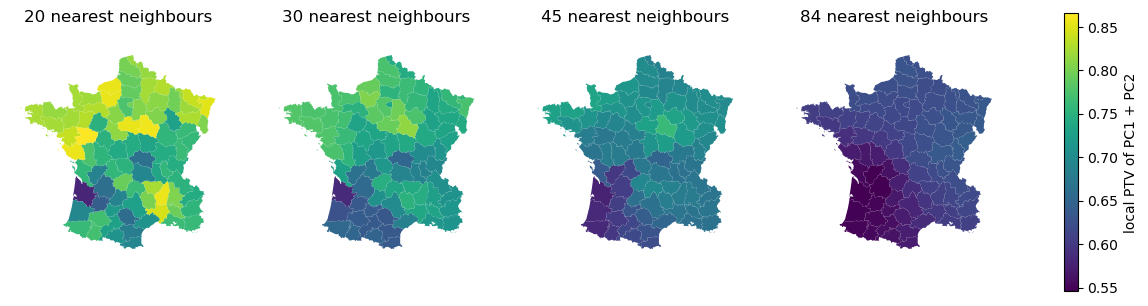

In [21]:
ptv = pd.DataFrame({bw: m.proportion_total_var_ for bw, m in fits.items()})
norm = plt.Normalize(ptv.min().min(), ptv.max().max())

fig, axes = plt.subplots(1, len(bandwidths), figsize=(16, 4.5))
for ax, bw in zip(axes, bandwidths, strict=True):
    gdf.assign(ptv=ptv[bw]).plot("ptv", ax=ax, cmap="viridis", norm=norm)
    ax.set_title(f"{bw} nearest neighbours")
    ax.set_axis_off()
fig.colorbar(
    plt.cm.ScalarMappable(cmap="viridis", norm=norm),
    ax=axes,
    shrink=0.8,
    label="local PTV of PC1 + PC2",
);

With 84 neighbours (all but one department) the median local PTV drops to
0.61, approaching the global 0.56, and some departments fall below the global
value. The bisquare kernel still down-weights distant departments, so even this
fit is not quite the global PCA.

How similar are the maps? The rank correlation of local PTV between
bandwidths:

In [22]:
ptv.corr(method="spearman").round(2)

,20,30,45,84
20,1.00,0.84,0.61,0.35
30,0.84,1.00,0.84,0.44
45,0.61,0.84,1.00,0.67
84,0.35,0.44,0.67,1.00


Neighbouring bandwidths agree fairly well, but the pattern shifts as the
bandwidth changes, so the results depend on the bandwidth, not only on the
data. That calls for a principled way to choose it.

## Choosing the bandwidth by cross-validation

{cite:t}`harris2011` choose the bandwidth by leave-one-out cross-validation.
For each department:

1. fit the local PCA at its location **without** that department
   (`include_focal=False` drops each location's own weight);
2. reconstruct the department's values from the first two local components;
3. measure what the reconstruction misses: the sum of squared residuals.

Adding these residuals up gives a score for the bandwidth; the bandwidth with
the smallest score reconstructs unseen departments best. Leaving each
department out matters: otherwise the smallest bandwidth always wins, because
a neighbourhood made mostly of the department itself reconstructs it almost
perfectly.

```{note}
`spml` will provide this as part of its bandwidth search. Until then, the
function below computes it from a fitted model. It reads the local means from
`_local_models`, an internal attribute filled when `keep_models=True`, which is
why it may change in future releases.
```

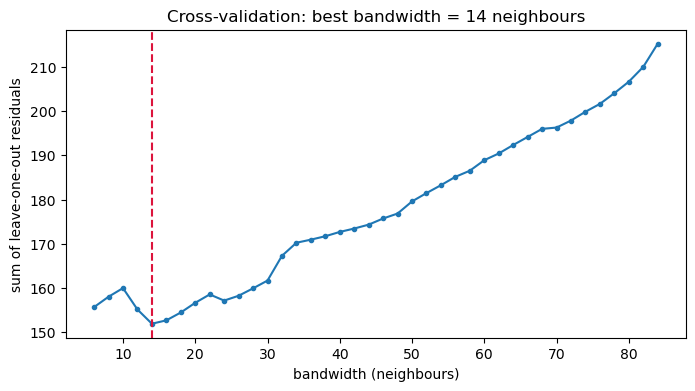

In [23]:
X_values = X_std.to_numpy()


def loo_residuals(bandwidth, n_components=2):
    """Leave-one-out reconstruction error of every department."""
    model = GWPCA(
        n_components=n_components,
        bandwidth=bandwidth,
        fixed=False,
        include_focal=False,  # leave each department out of its own fit
        keep_models=True,
        fit_global_model=False,
    ).fit(X, geometry=points)
    residuals = pd.Series(np.nan, index=gdf.index)
    for loc, local in model._local_models.items():
        centred = X_values[loc] - local["mean"]  # centre on the local mean
        V = local["components"].T  # (n_features, n_components)
        residuals[loc] = np.sum((centred - centred @ V @ V.T) ** 2)
    return residuals


cv = pd.Series(
    {bw: loo_residuals(bw).sum() for bw in range(6, 85, 2)},
    name="CV score",
).rename_axis("bandwidth (neighbours)")

best_bw = cv.idxmin()
ax = cv.plot(marker=".", figsize=(8, 4))
ax.axvline(best_bw, color="crimson", ls="--")
ax.set_ylabel("sum of leave-one-out residuals")
ax.set_title(f"Cross-validation: best bandwidth = {best_bw} neighbours");

The score is lowest for small neighbourhoods, up to about 30 departments,
then jumps and keeps rising: large neighbourhoods approach the global PCA and
miss local structure. Below 30 the curve is bumpy but low, so several
bandwidths there are nearly as good as the minimum. The evidence is for "a
small neighbourhood" more than for one exact number.

```{note}
`GWmodel`'s `bw.gwpca` computes a different score, so it can choose a
different bandwidth on the same data. It reconstructs each observation without
subtracting the local mean, and squares the *sum* of the residuals rather than
summing their squares, so positive and negative residuals cancel. Here, that
score picks a bandwidth of about 44 neighbours.
```

Refit at the selected bandwidth and redraw the main maps:

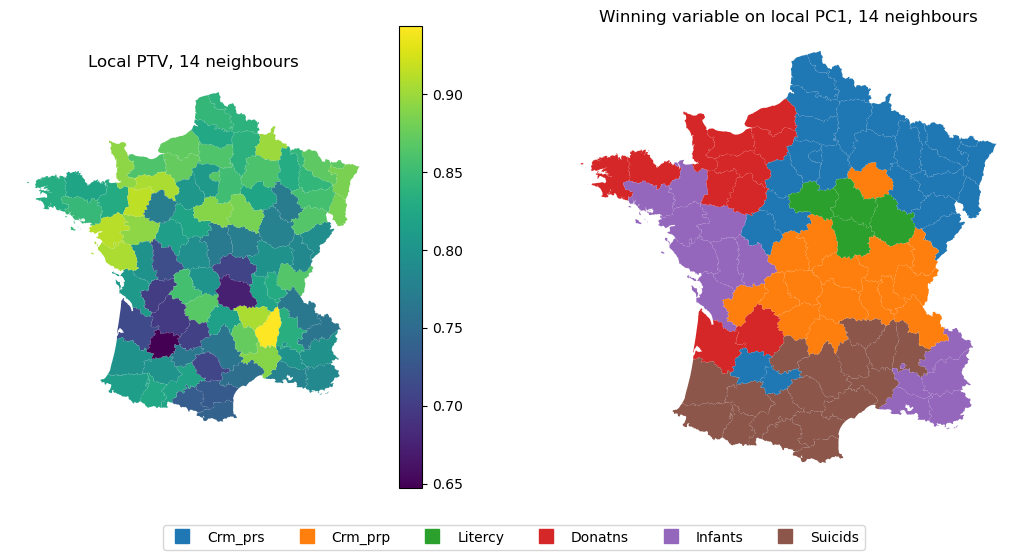

In [24]:
gwpca_cv = GWPCA(n_components=2, bandwidth=best_bw, fixed=False).fit(X, geometry=points)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
gdf.assign(ptv=gwpca_cv.proportion_total_var_).plot(
    "ptv", ax=axes[0], cmap="viridis", legend=True
)
axes[0].set_title(f"Local PTV, {best_bw} neighbours")
gdf.plot(color=gwpca_cv.winning_variable_.map(colors), ax=axes[1])
axes[1].set_title(f"Winning variable on local PC1, {best_bw} neighbours")
for ax in axes:
    ax.set_axis_off()
fig.legend(handles, colors.keys(), loc="lower center", ncol=len(variables));

With the smaller, cross-validated neighbourhood, local PTV is higher and
spans a wider range than with 30 neighbours, while the winning-variable regions
stay broadly the same.

## Local outliers

The leave-one-out residuals have a second use. A department whose values are
badly reconstructed from its neighbours' local components has an unusual
*combination* of values compared with its neighbours: a multivariate **local**
outlier. It need not be unusual for France as a whole, which is what the global
outliers above measured.

Dprtmnt
Creuse                 14.42
Calvados               13.72
Vendee                 10.39
Allier                  6.55
Pyrenees-Orientales     5.58
Hautes-Pyrenees         5.56
Haute-Loire             4.44
Hautes-Alpes            4.43
dtype: float64

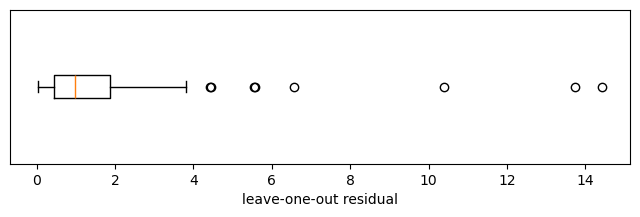

In [25]:
residuals = loo_residuals(best_bw).set_axis(gdf["Dprtmnt"])

fig, ax = plt.subplots(figsize=(8, 2))
ax.boxplot(residuals, vert=False)
ax.set_yticks([])
ax.set_xlabel("leave-one-out residual")

local_outliers = boxplot_outliers(residuals)
residuals[local_outliers].sort_values(ascending=False).round(2)

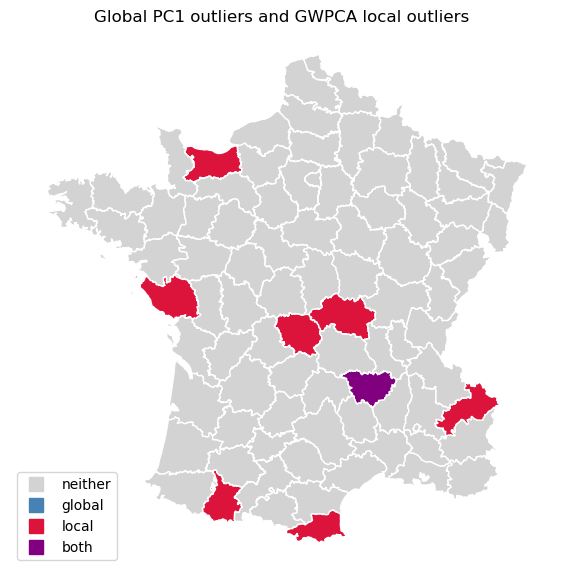

In [26]:
outlier_map = pd.Series("neither", index=gdf.index)
outlier_map[gdf["Dprtmnt"].isin(global_outliers)] = "global"
outlier_map[gdf["Dprtmnt"].isin(local_outliers)] = "local"
outlier_map[
    gdf["Dprtmnt"].isin(global_outliers) & gdf["Dprtmnt"].isin(local_outliers)
] = "both"

palette = {
    "neither": "lightgrey",
    "global": "steelblue",
    "local": "crimson",
    "both": "purple",
}
ax = gdf.plot(color=outlier_map.map(palette), edgecolor="white", figsize=(7, 7))
ax.legend(
    [plt.Line2D([], [], marker="s", ls="", color=c, ms=10) for c in palette.values()],
    palette.keys(),
    loc="lower left",
)
ax.set_title("Global PC1 outliers and GWPCA local outliers")
ax.set_axis_off()

Haute-Loire, the single global outlier, is also a local outlier. The other
local outliers are unremarkable on the global PC1 and only stand out against
their neighbours.

### Why is it an outlier?

A geographically weighted parallel-coordinates plot shows what sets a local
outlier apart from its neighbours. Each department is a line across the six
standardized variables; the outlier is drawn in red and its neighbours in
grey, fading with distance (using the same bisquare kernel as the fit).

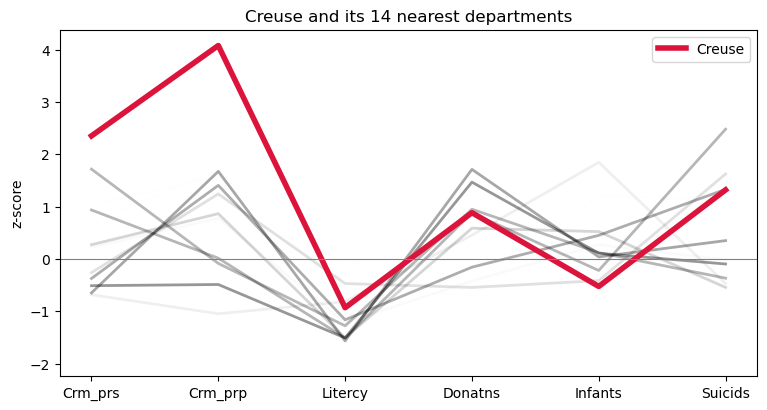

In [27]:
def gw_parallel_coordinates(name, n_neighbours, ax):
    i = gdf.index[gdf["Dprtmnt"] == name][0]
    dist = points.distance(points.iloc[i])
    nearest = dist.drop(i).nsmallest(n_neighbours)
    weights = (1 - (nearest / nearest.max()) ** 2) ** 2  # bisquare
    span = np.arange(len(variables))
    for j, w in weights.items():
        ax.plot(span, X_std.loc[j], color="black", alpha=0.6 * w, lw=2)
    ax.plot(span, X_std.loc[i], color="crimson", lw=4, label=name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(span, variables)
    ax.set_ylabel("z-score")
    ax.legend()


top = residuals.idxmax()
fig, ax = plt.subplots(figsize=(9, 4.5))
gw_parallel_coordinates(top, best_bw, ax)
ax.set_title(f"{top} and its {best_bw} nearest departments");

Creuse stands out through crime: crimes against property are about four
standard deviations above the national mean, and crimes against persons are
also high, well above every one of its neighbours. On the other variables it
looks like its neighbours. The z-scores are global, so in general a variable
can be unremarkable for France and still stand out locally.

## What is not covered yet

Two parts of a full GWPCA analysis are not yet available in `spml`:

- **A Monte Carlo test** of whether the local variation is larger than random
  spatial arrangements of the same data would produce {cite:p}`harris2011`.
  Local eigenvalues always vary somewhat, so without this test some of the
  patterns above could be noise.
- **Aligning components across locations**, so that loading maps and glyphs
  are free of sign flips and component swaps.